In [ ]:

import pandas as pd
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nData Types:")
print(df.dtypes)

Rows: 8807
Columns: 12

Data Types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object


A2 : calculating missing values, duplicate values,incorrect data types, inconisistent data values and outliers


In [ ]:
missing = df.isnull().sum()
missing_percent = df.isnull().mean() * 100

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent.round(2)
})

print(missing_table)

              Missing Count  Missing Percentage
show_id                   0                0.00
type                      0                0.00
title                     0                0.00
director               2634               29.91
cast                    825                9.37
country                 831                9.44
date_added               10                0.11
release_year              0                0.00
rating                    4                0.05
duration                  3                0.03
listed_in                 0                0.00
description               0                0.00


In [ ]:
columns = ["director", "cast", "country","date_added", "rating", "duration"]

for col in columns:
    print("\n", col)
    print(df.groupby("type")[col].apply(
        lambda x: round(x.isnull().mean() * 100, 2)
    ))


 director
type
Movie       3.07
TV Show    91.41
Name: director, dtype: float64

 cast
type
Movie       7.75
TV Show    13.08
Name: cast, dtype: float64

 country
type
Movie       7.18
TV Show    14.61
Name: country, dtype: float64

 date_added
type
Movie      0.00
TV Show    0.37
Name: date_added, dtype: float64

 rating
type
Movie      0.03
TV Show    0.07
Name: rating, dtype: float64

 duration
type
Movie      0.05
TV Show    0.00
Name: duration, dtype: float64


In [ ]:
print("Full-row duplicates:", df.duplicated().sum())
print("Duplicate IDs:", df.duplicated(subset="show_id").sum())
print("Repeated title/type combinations:", df.duplicated(subset=["title", "type"]).sum())

Full-row duplicates: 0
Duplicate IDs: 0
Repeated title/type combinations: 0


In [ ]:
print(df[["date_added", "duration"]].dtypes)

print(df["duration"].dropna().sample(10, random_state=42))

dates = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)
print("Invalid or missing dates:", dates.isnull().sum())

date_added    object
duration      object
dtype: object
95      3 Seasons
3349       97 min
4687     1 Season
2816     1 Season
360       125 min
5516      106 min
4011       98 min
6830      107 min
3412      112 min
2465      116 min
Name: duration, dtype: object
Invalid or missing dates: 10


In [ ]:
print("Content types:")
print(df["type"].value_counts(dropna=False))

print("\nRatings:")
print(df["rating"].value_counts(dropna=False))

print("\nRatings containing 'min':")
print(df[df["rating"].fillna("").str.contains("min")][
    ["show_id", "title", "rating", "duration"]
])

Content types:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Ratings:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: count, dtype: int64

Ratings containing 'min':
     show_id                                 title  rating duration
5541   s5542                       Louis C.K. 2017  74 min      NaN
5794   s5795                 Louis C.K.: Hilarious  84 min      NaN
5813   s5814  Louis C.K.: Live at the Comedy Store  66 min      NaN


In [ ]:
print("Release year range:")
print(df["release_year"].min(), df["release_year"].max())

print("\nRelease year summary:")
print(df["release_year"].describe())

print("\nDuration examples:")
print(df["duration"].value_counts().head(10))

q1 = df["release_year"].quantile(0.25)
q3 = df["release_year"].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[
    (df["release_year"] < lower) |
    (df["release_year"] > upper)
]
print("IQR lower limit:", lower)
print("IQR upper limit:", upper)
print("Potential outliers:", len(outliers))
outliers[["title", "type", "release_year"]].head(10)

Release year range:
1925 2021

Release year summary:
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Duration examples:
duration
1 Season     1793
2 Seasons     425
3 Seasons     199
90 min        152
97 min        146
94 min        146
93 min        146
91 min        144
95 min        137
96 min        130
Name: count, dtype: int64
IQR lower limit: 2004.0
IQR upper limit: 2028.0
Potential outliers: 719


,title,type,release_year
7,Sankofa,Movie,1993
22,Avvai Shanmughi,Movie,1996
24,Jeans,Movie,1998
26,Minsara Kanavu,Movie,1997
41,Jaws,Movie,1975
42,Jaws 2,Movie,1978
43,Jaws 3,Movie,1983
44,Jaws: The Revenge,Movie,1987
48,Training Day,Movie,2001
51,InuYasha the Movie 2: The Castle Beyond the Lo...,Movie,2002


In [ ]:
clean = df.copy()

for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].str.strip()

print("Dataset shape:", clean.shape)

Dataset shape: (8807, 12)


Three movie durations were incorrectly stored in the rating column.
These values were moved to duration, and the corresponding ratings
were marked as missing because the actual maturity ratings are
unknown.

In [ ]:
mask = clean["rating"].fillna("").str.contains( r"^\d+\s*min$", regex=True)

print(clean.loc[mask, ["title", "rating", "duration"]])

clean.loc[mask, "duration"] = clean.loc[mask, "rating"]
clean.loc[mask, "rating"] = np.nan

print("Misplaced durations corrected:", mask.sum())

                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN
Misplaced durations corrected: 3


Missing categorical values were replaced with "Unknown".

Ten missing dates remain because their actual values are unavailable.
This preserves all records, although titles with missing dates
cannot be included in year-added analysis.

The Unknown category will be excluded when ranking actual
countries or maturity ratings.

In [ ]:
for col in ["director", "cast", "country", "rating"]:
    clean[col] = clean[col].fillna("Unknown")

clean["date_added"] = pd.to_datetime(
    clean["date_added"], errors="coerce"
)

print(clean.isnull().sum())

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [ ]:
clean["date_added"] = pd.to_datetime(clean["date_added"], errors="coerce")
clean["year_added"] = clean["date_added"].dt.year

clean["release_gap"] = (
    clean["year_added"] - clean["release_year"]
)

print(clean[[
    "release_year", "year_added", "release_gap"
]].head())

   release_year  year_added  release_gap
0          2020      2021.0          1.0
1          2021      2021.0          0.0
2          2021      2021.0          0.0
3          2021      2021.0          0.0
4          2021      2021.0          0.0


Movie durations and TV-show season counts are now stored as
separate numerical variables.

This prevents misleading comparisons between minutes and seasons.
Missing values in these columns are expected for the opposite
content type and do not indicate data quality problems.

In [ ]:
# Extract the number from duration
clean["duration_number"] = pd.to_numeric(
    clean["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Separate movie and TV-show durations
clean["movie_minutes"] = clean["duration_number"].where(
    clean["type"] == "Movie"
)

clean["seasons"] = clean["duration_number"].where(
    clean["type"] == "TV Show"
)

# Remove temporary column
clean.drop(columns="duration_number", inplace=True)

print(clean[[
    "type", "duration", "movie_minutes", "seasons"
]].head(10))

      type   duration  movie_minutes  seasons
0    Movie     90 min           90.0      NaN
1  TV Show  2 Seasons            NaN      2.0
2  TV Show   1 Season            NaN      1.0
3  TV Show   1 Season            NaN      1.0
4  TV Show  2 Seasons            NaN      2.0
5  TV Show   1 Season            NaN      1.0
6    Movie     91 min           91.0      NaN
7    Movie    125 min          125.0      NaN
8  TV Show  9 Seasons            NaN      9.0
9    Movie    104 min          104.0      NaN


The number of countries and genres associated with each title
has been calculated.

Unknown countries are assigned a count of zero, indicating
that no country information is available, rather than proving
that the title has no country of origin.

The original multi-valued columns are preserved for later analysis.

In [ ]:
clean["num_countries"] = clean["country"].apply(
    lambda x: 0 if pd.isna(x) or x == "Unknown" else len(str(x).split(","))
)

clean["num_genres"] = clean["listed_in"].apply(
    lambda x: 0 if pd.isna(x) else len(str(x).split(","))
)

print(clean[[
    "country", "num_countries",
    "listed_in", "num_genres"
]].head())

         country  num_countries  \
0  United States              1   
1   South Africa              1   
2        Unknown              0   
3        Unknown              0   
4          India              1   

                                           listed_in  num_genres  
0                                      Documentaries           1  
1    International TV Shows, TV Dramas, TV Mysteries           3  
2  Crime TV Shows, International TV Shows, TV Act...           3  
3                             Docuseries, Reality TV           2  
4  International TV Shows, Romantic TV Shows, TV ...           3  


In [ ]:
# Check negative release gaps
negative_gap = clean[clean["release_gap"] < 0]

print("Negative release gaps:", len(negative_gap))

print(negative_gap[[
    "title", "release_year", "year_added", "release_gap"
]])

# Check unusually short and long movies
movies = clean[clean["type"] == "Movie"]

print("\nShortest movies:")
print(movies.nsmallest(5, "movie_minutes")[
    ["title", "movie_minutes"]
])

print("\nLongest movies:")
print(movies.nlargest(5, "movie_minutes")[
    ["title", "movie_minutes"]
])

# Check TV Shows with most seasons
shows = clean[clean["type"] == "TV Show"]

print("\nShows with most seasons:")
print(shows.nlargest(5, "seasons")[
    ["title", "seasons"]
])

Negative release gaps: 14
                           title  release_year  year_added  release_gap
1551                       Hilda          2021      2020.0         -1.0
1696                Polly Pocket          2021      2020.0         -1.0
2920               Love Is Blind          2021      2020.0         -1.0
3168                Fuller House          2020      2019.0         -1.0
3287          Maradona in Mexico          2020      2019.0         -1.0
3369             BoJack Horseman          2020      2019.0         -1.0
3433            The Hook Up Plan          2020      2019.0         -1.0
4844   Unbreakable Kimmy Schmidt          2019      2018.0         -1.0
4845        Arrested Development          2019      2018.0         -1.0
5394  Hans Teeuwen: Real Rancour          2018      2017.0         -1.0
5658                      Sense8          2018      2016.0         -2.0
5677                 Tokyo Trial          2017      2016.0         -1.0
7063                    Incoming      

In [ ]:
print("Final dataset shape:", clean.shape)

print("\nDuplicate IDs:")
print(clean["show_id"].duplicated().sum())

print("\nMissing values:")
print(clean.isnull().sum())

print("\nData types:")
print(clean.dtypes)

Final dataset shape: (8807, 18)

Duplicate IDs:
0

Missing values:
show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added         10
release_year        0
rating              0
duration            0
listed_in           0
description         0
year_added         10
release_gap        10
movie_minutes    2676
seasons          6131
num_countries       0
num_genres          0
dtype: int64

Data types:
show_id                  object
type                     object
title                    object
director                 object
cast                     object
country                  object
date_added       datetime64[ns]
release_year              int64
rating                   object
duration                 object
listed_in                object
description              object
year_added              float64
release_gap             float64
movie_minutes           float64
seasons                 float64

### Final Data Validation

After cleaning, missing categorical values in director, cast,
country and rating were replaced with "Unknown".

Three misplaced duration values were corrected, resulting in
no missing movie durations.

Ten missing date_added values were retained because their
actual dates are unknown. Consequently, year_added and
release_gap also contain ten missing values.

The movie_minutes column contains 2,676 missing values
corresponding to TV Shows, while seasons contains 6,131
missing values corresponding to Movies. These are expected
because the two variables measure different content types.

The dataset contains 8,807 records and 18 columns, with
no duplicate show_id values.

In [ ]:
# Correct misplaced duration values
mask = clean["rating"].fillna("").str.contains(
    r"^\d+\s*min$", regex=True
)

clean.loc[mask, "duration"] = clean.loc[mask, "rating"]
clean.loc[mask, "rating"] = np.nan

# Fill missing categorical values
for col in ["director", "cast", "country", "rating"]:
    clean[col] = clean[col].fillna("Unknown")

# Update movie_minutes after correcting duration
movie_mask = clean["type"] == "Movie"

clean.loc[movie_mask, "movie_minutes"] = pd.to_numeric(
    clean.loc[movie_mask, "duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Update number of countries
clean["num_countries"] = clean["country"].apply(
    lambda x: 0 if x == "Unknown" else len(x.split(","))
)

# Check again
print(clean.isnull().sum())

show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added         10
release_year        0
rating              0
duration            0
listed_in           0
description         0
year_added         10
release_gap        10
movie_minutes    2676
seasons          6131
num_countries       0
num_genres          0
dtype: int64


In [ ]:
clean.to_csv(
    "23L_0646_A2_netflix_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Percentages:
type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


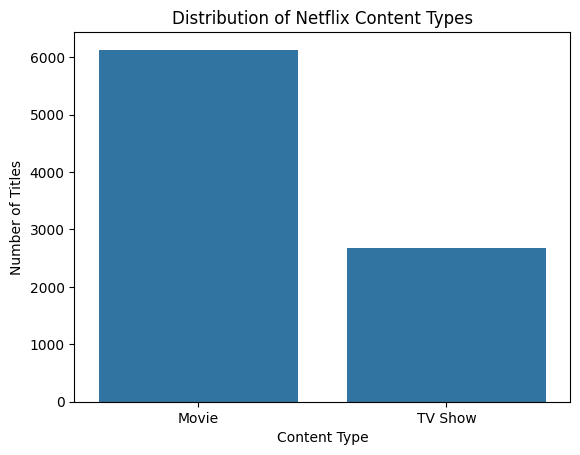

In [ ]:
print(clean["type"].value_counts())

print("\nPercentages:")
print((clean["type"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=clean, x="type")
plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

Movies account for approximately 69.6% of the dataset, while
TV Shows represent 30.4%.

This indicates that Movies are more common than TV Shows in
the Netflix catalogue.

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Skewness: -3.4465650403316013


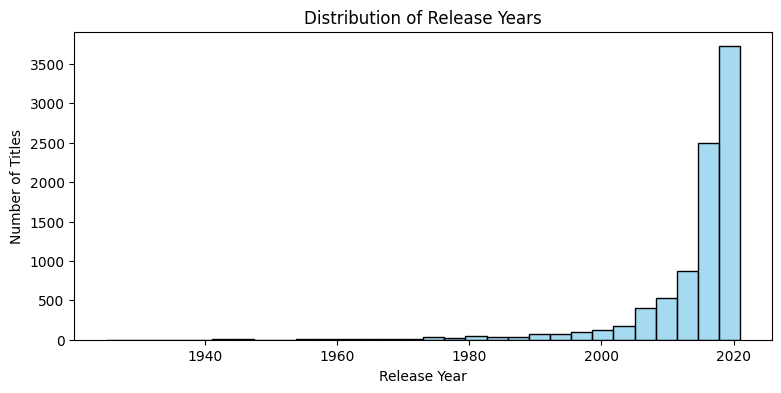

In [ ]:
print(clean["release_year"].describe())

print("\nSkewness:", clean["release_year"].skew())

plt.figure(figsize=(9, 4))

sns.histplot(
    clean["release_year"],
    bins=30,
    color="skyblue"
)

plt.title("Distribution of Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

The release-year distribution is concentrated in more recent
years, with a longer tail extending toward older releases.

The distribution is left skewed because most titles are
relatively recent, while fewer titles were released many
decades ago.


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
Unknown        7
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Percentages:
rating
TV-MA       36.41
TV-14       24.53
TV-PG        9.80
R            9.07
PG-13        5.56
TV-Y7        3.79
TV-Y         3.49
PG           3.26
TV-G         2.50
NR           0.91
G            0.47
Unknown      0.08
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
Name: proportion, dtype: float64


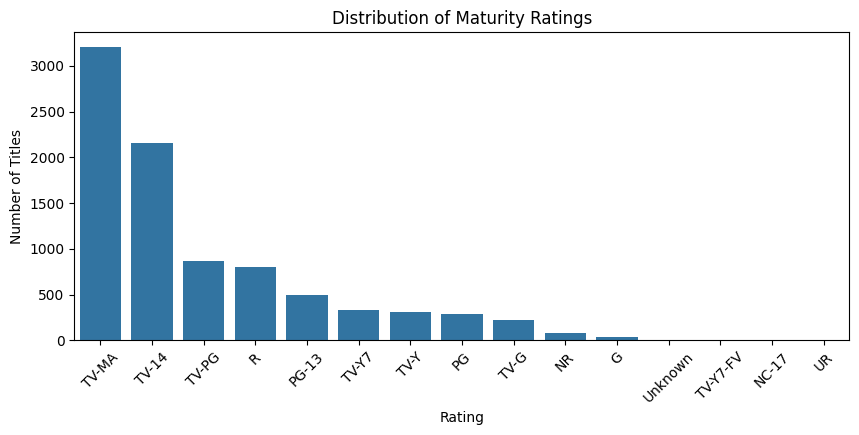

In [ ]:
print(clean["rating"].value_counts())

print("\nPercentages:")
print((clean["rating"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(10, 4))

sns.countplot(
    data=clean,
    x="rating",
    order=clean["rating"].value_counts().index
)

plt.title("Distribution of Maturity Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

TV-MA and TV-14 are among the most frequently occurring
maturity ratings.

This indicates that a large portion of the catalogue consists
of content classified for mature or teenage audiences.

The Unknown category represents titles whose ratings were
missing and should not be interpreted as a real maturity rating.

count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_minutes, dtype: float64

Skewness: 0.20337565111840317


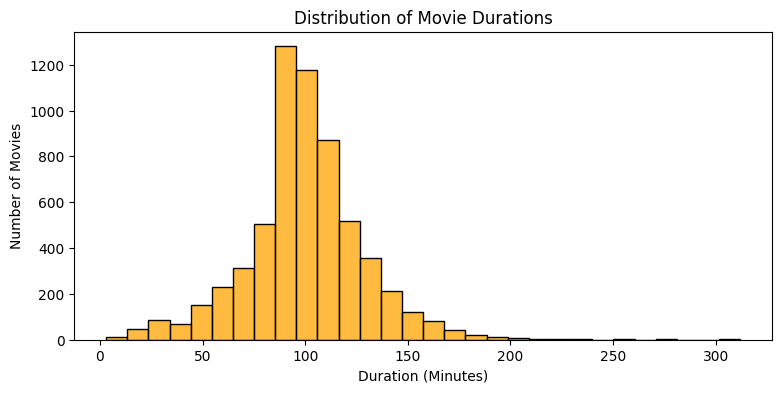

In [ ]:
movies = clean[clean["type"] == "Movie"]

print(movies["movie_minutes"].describe())

print("\nSkewness:", movies["movie_minutes"].skew())

plt.figure(figsize=(9, 4))

sns.histplot(
    movies["movie_minutes"].dropna(),
    bins=30,
    color="orange"
)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.show()

Most movies are concentrated around typical feature-film
durations, with a median of approximately 98 minutes.

Some movies are much shorter or longer than average, producing
a wider spread in the distribution.
These unusual durations were retained because short films
and lengthy movies may be valid.

count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: seasons, dtype: float64

Skewness: 3.4185670153744647


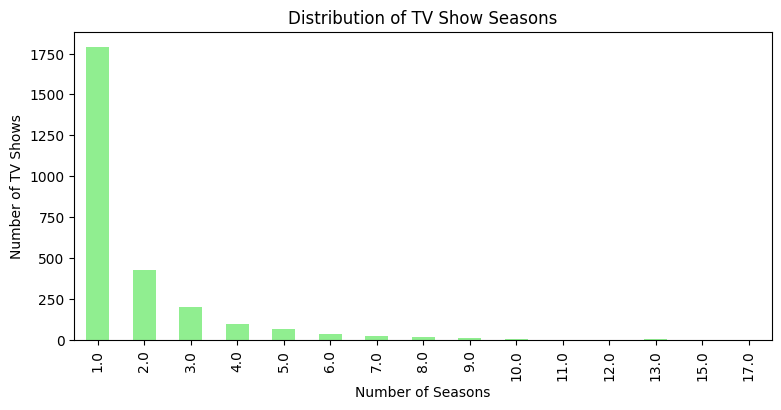

In [ ]:
shows = clean[clean["type"] == "TV Show"]

print(shows["seasons"].describe())

print("\nSkewness:", shows["seasons"].skew())

plt.figure(figsize=(9, 4))

shows["seasons"].value_counts().sort_index().plot(
    kind="bar",
    color="lightgreen"
)

plt.title("Distribution of TV Show Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.show()

Most TV Shows have only one season, and the frequency generally
decreases as the number of seasons increases.

The median season count is 1, indicating that at least half
of the TV Shows have one season.

The distribution is positively skewed because a small number
of shows have many seasons.

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


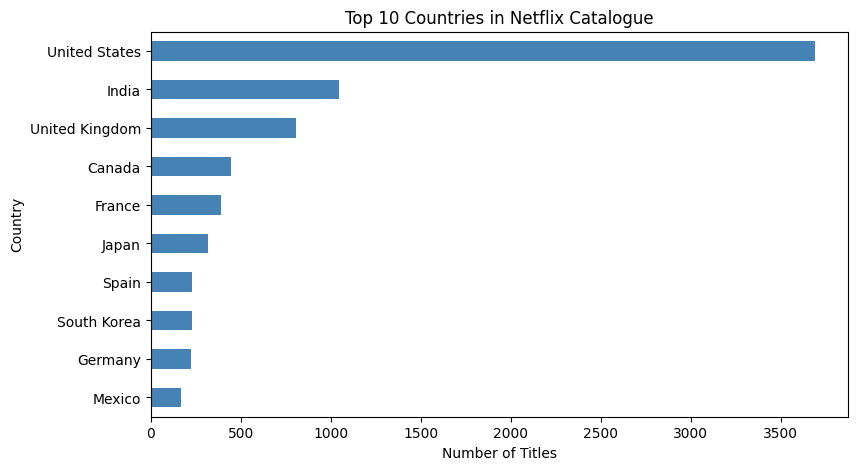

In [ ]:
countries = clean["country"].str.split(",").explode()

countries = countries.str.strip()

countries = countries[
    (countries != "Unknown") & countries.notna()
]

top_countries = countries.value_counts().head(10)

print(top_countries)

plt.figure(figsize=(9, 5))

top_countries.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Countries in Netflix Catalogue")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

The United States is the most frequently represented country,
followed by India and the United Kingdom.

The counts include countries appearing in multi-country
productions, so a single title may contribute to more
than one country.

Unknown country values were excluded from the ranking.

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


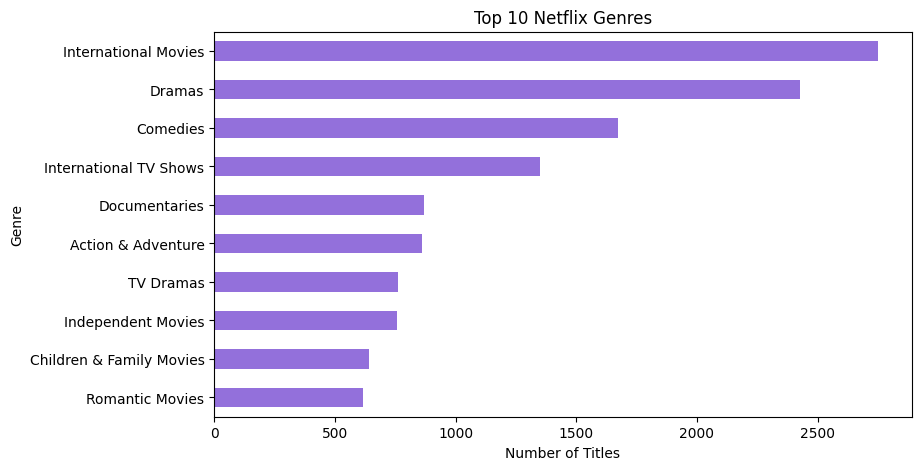

In [ ]:
genres = clean["listed_in"].str.split(",").explode()

genres = genres.str.strip()

top_genres = genres.value_counts().head(10)

print(top_genres)

plt.figure(figsize=(9, 5))

top_genres.sort_values().plot(
    kind="barh",
    color="mediumpurple"
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()

International Movies, Dramas and Comedies are among the most
frequently occurring genre labels.

This shows that these categories have strong representation
in the Netflix catalogue.

Since a title may belong to multiple genres, the total genre
frequencies can exceed the total number of titles.

Correlation: 0.112


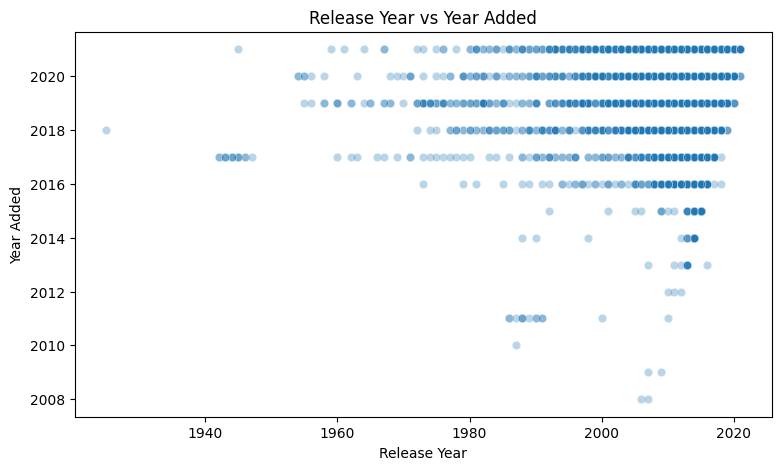

In [ ]:
# Calculate correlation
correlation = clean["release_year"].corr(clean["year_added"])

print("Correlation:", round(correlation, 3))

# Scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=clean,
    x="release_year",
    y="year_added",
    alpha=0.3
)

plt.title("Release Year vs Year Added")
plt.xlabel("Release Year")
plt.ylabel("Year Added")
plt.show()

Shows virtually no linear relationship between when content was released and when it was added. Most titles are heavily clustered around 2016–2021+ and released post-2000, reflecting the platform's rapid expansion and strong focus on modern content.

         count     mean  median   std   min   max
type                                             
Movie     6131  2013.12  2016.0  9.68  1942  2021
TV Show   2676  2016.61  2018.0  5.74  1925  2021


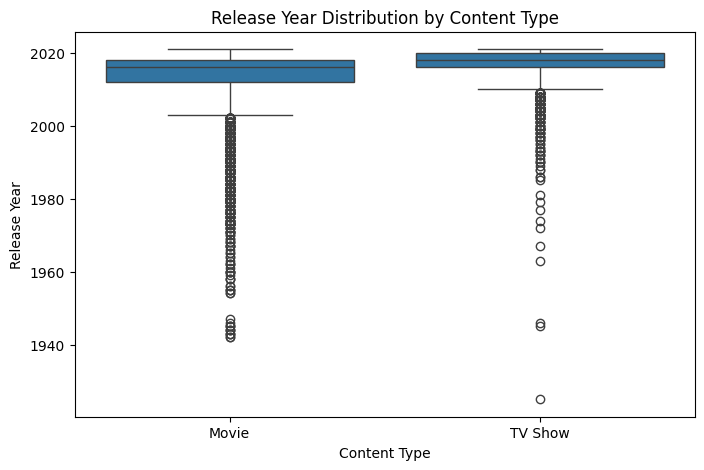

In [ ]:
# Descriptive statistics
print(clean.groupby("type")["release_year"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2))

# Box plot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean,
    x="type",
    y="release_year"
)

plt.title("Release Year Distribution by Content Type")
plt.xlabel("Content Type")
plt.ylabel("Release Year")
plt.show()

Compares the release age between Movies and TV Shows, showing that TV Shows are generally newer with a much tighter, recent median distribution. Movies feature a broader age spread and a long tail of older catalog outliers extending back to the 1940s.

Rating Counts:
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        5
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      733
TV-G        126       94
TV-MA      2062     1145
TV-PG       540      323
TV-Y        131      176
TV-Y7       139      195
TV-Y7-FV      5        1
UR            3        0
Unknown       5        2

Rating Percentages:
type      Movie  TV Show
rating                  
G          0.67     0.00
NC-17      0.05     0.00
NR         1.22     0.19
PG         4.68     0.00
PG-13      7.99     0.00
R         13.00     0.07
TV-14     23.28    27.39
TV-G       2.06     3.51
TV-MA     33.63    42.79
TV-PG      8.81    12.07
TV-Y       2.14     6.58
TV-Y7      2.27     7.29
TV-Y7-FV   0.08     0.04
UR         0.05     0.00
Unknown    0.08     0.07


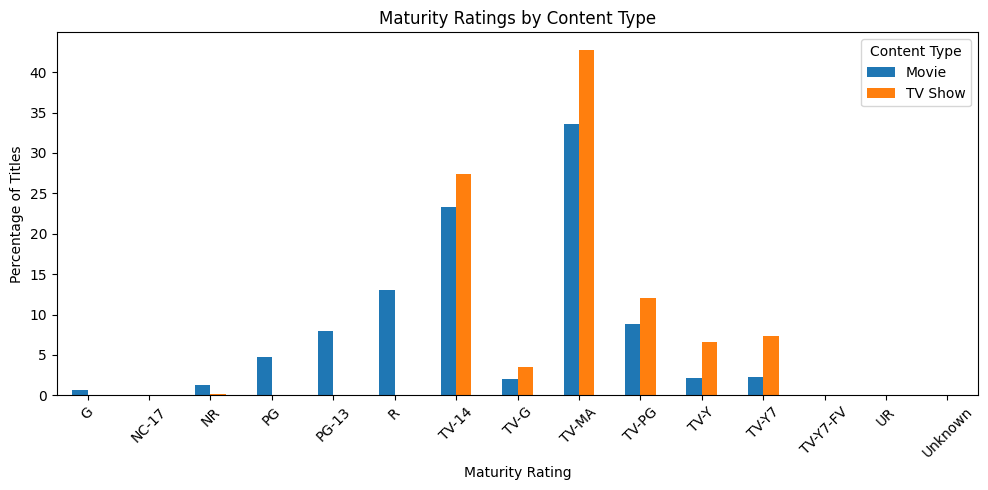

In [ ]:
# Cross-tabulation of counts
rating_counts = pd.crosstab(
    clean["rating"],
    clean["type"]
)

print("Rating Counts:")
print(rating_counts)

# Percentages within each content type
rating_percent = pd.crosstab(
    clean["rating"],
    clean["type"],
    normalize="columns"
) * 100

print("\nRating Percentages:")
print(rating_percent.round(2))

# Grouped bar chart
rating_percent.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Maturity Ratings by Content Type")
plt.xlabel("Maturity Rating")
plt.ylabel("Percentage of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

Compares the percentage share of maturity ratings between Movies and TV Shows across the library. TV-MA and TV-14 are the dominant categories for both formats, though TV Shows lean even more heavily into TV-MA over 40%. Film ratings like R, PG-13, and PG are exclusive to Movies, whereas children's categories like TV-Y and TV-Y7 make up a higher percentage of the TV library.  

Movie Correlation: 0.039
TV Show Correlation: 0.388


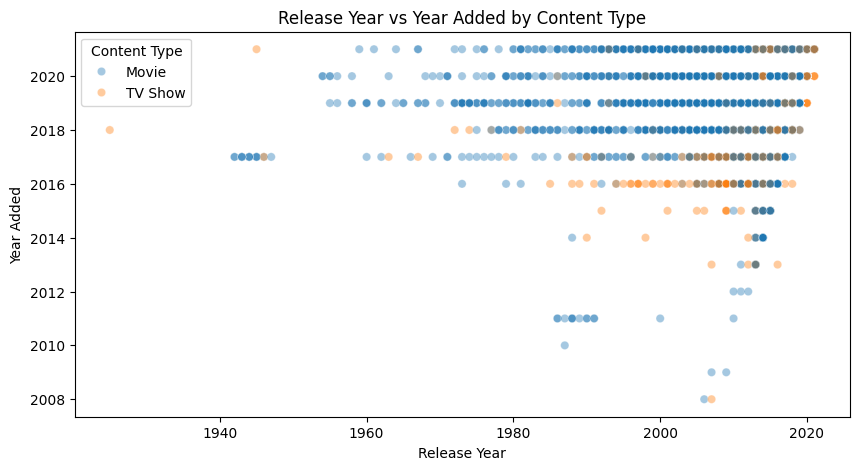

In [ ]:
# Compare correlations by content type
for content_type in ["Movie", "TV Show"]:
    subset = clean[clean["type"] == content_type]

    correlation = subset["release_year"].corr(
        subset["year_added"]
    )

    print(content_type, "Correlation:", round(correlation, 3))

# Scatter plot
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=clean,
    x="release_year",
    y="year_added",
    hue="type",
    alpha=0.4
)

plt.title("Release Year vs Year Added by Content Type")
plt.xlabel("Release Year")
plt.ylabel("Year Added")
plt.legend(title="Content Type")
plt.show()

Compares the relationship between a title's original release year and the year it was added, separated by Movies and TV Shows. Movies show virtually no correlation 0.039, meaning classic and modern films are added indiscriminately across all years. In contrast, TV Shows exhibit a stronger positive correlation 0.388, indicating that added TV series are significantly more tightly tied to recent release dates.

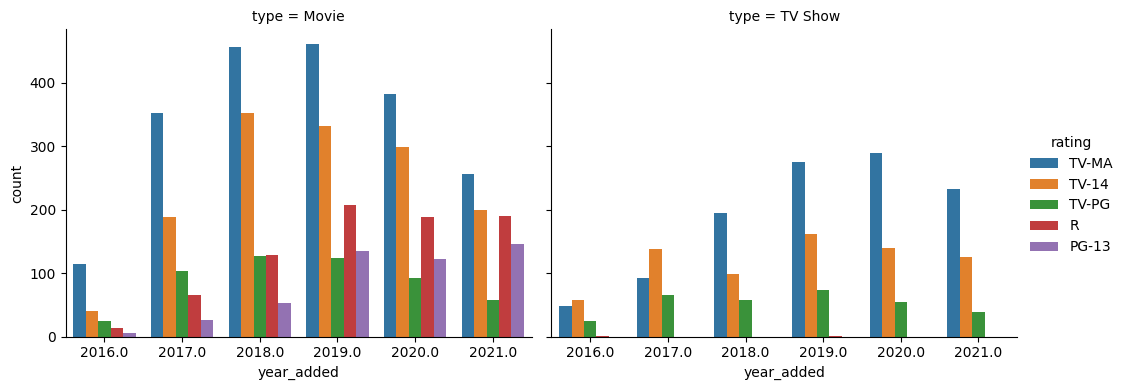

In [ ]:
# Select common ratings
top_ratings = clean[
    clean["rating"] != "Unknown"
]["rating"].value_counts().head(5).index

# Select years and ratings
data = clean[
    clean["year_added"].between(2016, 2021) &
    clean["rating"].isin(top_ratings)
].copy()

# Plot
sns.catplot(
    data=data,
    x="year_added",
    hue="rating",
    col="type",
    kind="count",
    height=4,
    aspect=1.3
)

plt.show()

Tracks annual catalog additions by rating for Movies and TV Shows, showing additions peaking overall around 2018–2019 before tapering off in 2020–2021. Across all years, TV-MA consistently remains the most added rating for both formats, followed by TV-14. Additionally, film-specific ratings like R and PG-13 show steady representation in Movies, whereas TV Shows are almost exclusively dominated by television ratings (TV-MA, TV-14, and TV-PG).

### A7.1 Movies and TV Shows Over Time

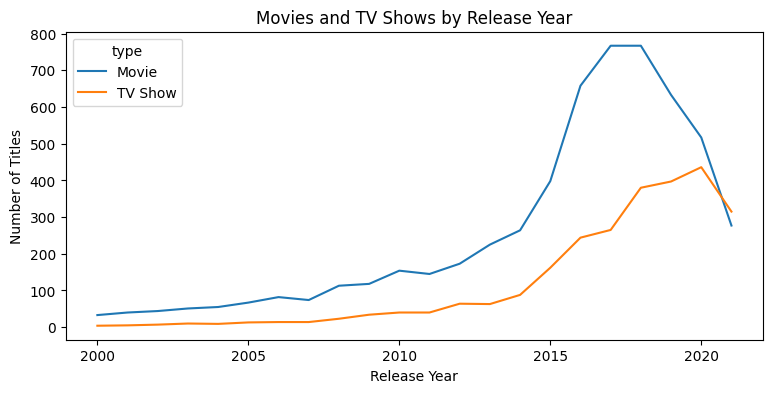

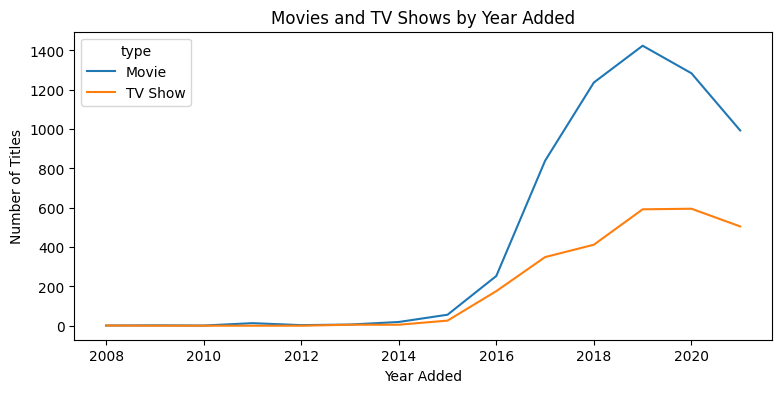

type         Movie  TV Show
year_added                 
2008.0       50.00    50.00
2009.0      100.00     0.00
2010.0      100.00     0.00
2011.0      100.00     0.00
2012.0      100.00     0.00
2013.0       54.55    45.45
2014.0       79.17    20.83
2015.0       68.29    31.71
2016.0       58.97    41.03
2017.0       70.62    29.38
2018.0       75.02    24.98
2019.0       70.63    29.37
2020.0       68.33    31.67
2021.0       66.29    33.71


In [ ]:
# Titles by release year
release_counts = pd.crosstab(
    clean["release_year"], clean["type"]
)

# Focus on 2000 onwards for readability
release_counts.loc[2000:].plot(figsize=(9, 4))

plt.title("Movies and TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()


# Titles by year added
added_counts = pd.crosstab(
    clean["year_added"], clean["type"]
)

added_counts.plot(figsize=(9, 4))

plt.title("Movies and TV Shows by Year Added")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.show()


# Percentage distribution by year added
added_percent = added_counts.div(
    added_counts.sum(axis=1), axis=0
) * 100

print(added_percent.round(2))

Movies are more common than TV Shows across most release and
addition years.
Movie additions increased significantly around 2017–2019,
while TV Show additions became more prominent in later years.
The dataset contains fewer additions in 2021, which may
reflect incomplete coverage of that year.

count    8783.000000
mean        4.697825
std         8.790808
min         0.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: release_gap, dtype: float64

Median gap by content type:
type
Movie      2.0
TV Show    0.0
Name: release_gap, dtype: float64


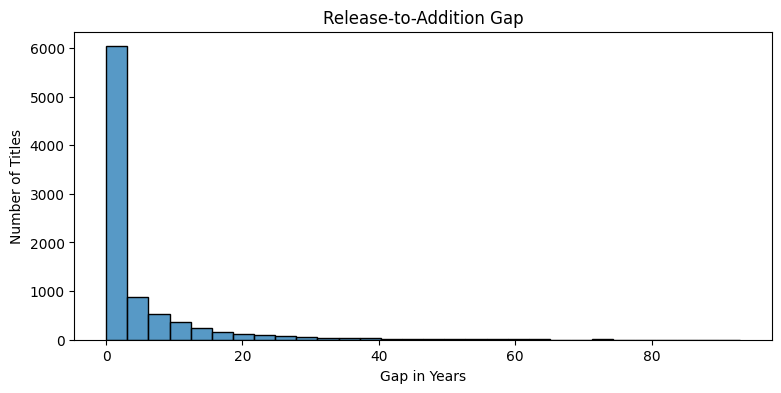

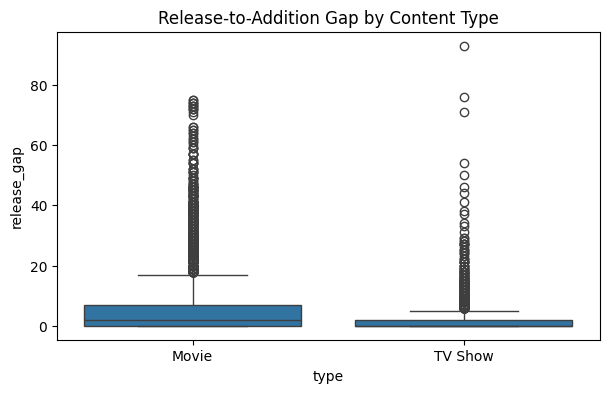

In [ ]:
# Exclude missing and negative gaps for this analysis
gap_data = clean[clean["release_gap"] >= 0]

print(gap_data["release_gap"].describe())

print("\nMedian gap by content type:")
print(gap_data.groupby("type")["release_gap"].median())

# Histogram
plt.figure(figsize=(9, 4))

sns.histplot(
    gap_data["release_gap"],
    bins=30
)

plt.title("Release-to-Addition Gap")
plt.xlabel("Gap in Years")
plt.ylabel("Number of Titles")
plt.show()


# Box plot
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=gap_data,
    x="type",
    y="release_gap"
)

plt.title("Release-to-Addition Gap by Content Type")
plt.show()

The release-to-addition gap is concentrated around smaller
values, indicating that many titles were added relatively
soon after their original release.

However, the distribution has a long right tail, showing
that some older titles were added decades later.


Top Countries:
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


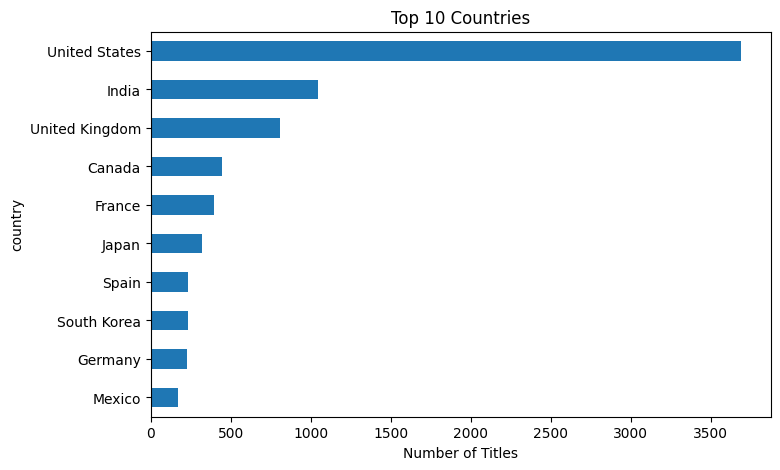


Top Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


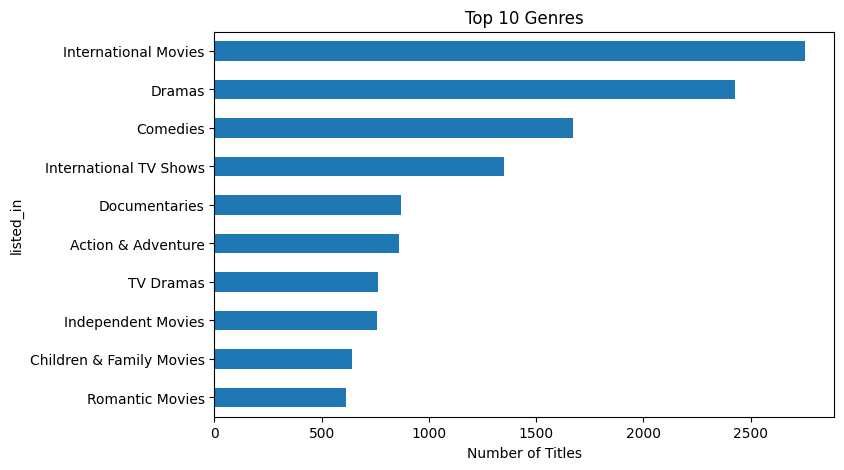

In [ ]:
# Count individual countries
countries = clean["country"].str.split(",").explode().str.strip()
countries = countries[countries != "Unknown"]

top_countries = countries.value_counts().head(10)

print("Top Countries:")
print(top_countries)

top_countries.sort_values().plot(
    kind="barh", figsize=(8, 5)
)

plt.title("Top 10 Countries")
plt.xlabel("Number of Titles")
plt.show()


# Count individual genres
genres = clean["listed_in"].str.split(",").explode().str.strip()

top_genres = genres.value_counts().head(10)

print("\nTop Genres:")
print(top_genres)

top_genres.sort_values().plot(
    kind="barh", figsize=(8, 5)
)

plt.title("Top 10 Genres")
plt.xlabel("Number of Titles")
plt.show()

Genre           Dramas  International Movies  Comedies  Documentaries  \
Country                                                                 
India             32.4                  42.3      15.8            1.3   
United Kingdom    29.8                  25.8      13.8           19.4   
United States     32.3                   6.4      26.3           19.8   

Genre           Independent Movies  
Country                             
India                          8.2  
United Kingdom                11.2  
United States                 15.1  


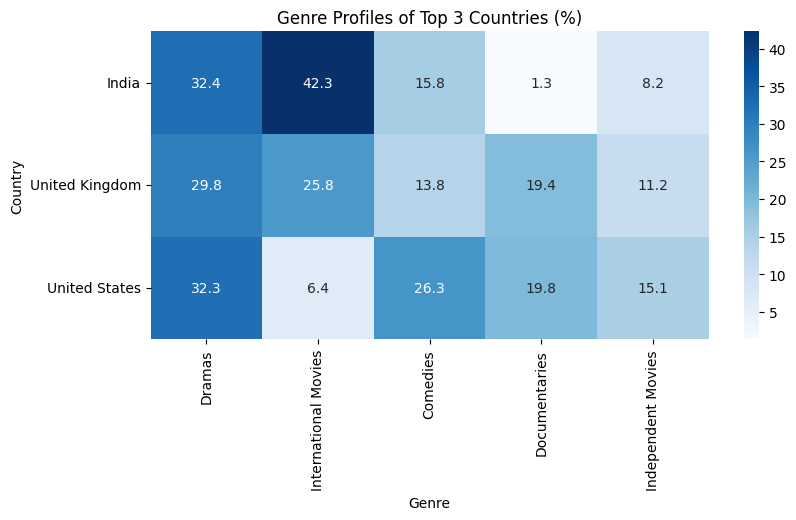

In [ ]:
# Select top 3 countries
top3 = top_countries.head(3).index

rows = []

for _, record in clean.iterrows():
    country_list = [
        c.strip() for c in record["country"].split(",")
    ]

    genre_list = [
        g.strip() for g in record["listed_in"].split(",")
    ]

    for country in country_list:
        if country in top3:
            for genre in genre_list:
                rows.append([country, genre])

country_genres = pd.DataFrame(
    rows, columns=["Country", "Genre"]
)

# Select most common genres
top5_genres = country_genres["Genre"].value_counts().head(5).index

genre_table = pd.crosstab(
    country_genres["Country"],
    country_genres["Genre"]
)[top5_genres]

# Convert to percentages within country
genre_percent = genre_table.div(
    genre_table.sum(axis=1), axis=0
) * 100

print(genre_percent.round(1))

plt.figure(figsize=(9, 4))

sns.heatmap(
    genre_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Genre Profiles of Top 3 Countries (%)")
plt.show()

The United States, India and the United Kingdom are among
the most represented countries.

International Movies, Dramas and Comedies are among the most
frequent genre labels.

The heatmap compares genre distributions across the leading
countries, showing that their genre profiles are not identical.

In [ ]:
# IQR outlier detection
for col in ["movie_minutes", "seasons"]:

    values = clean[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[
        (values < lower) | (values > upper)
    ]

    print(col)
    print("Potential outliers:", len(outliers))
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print()

movie_minutes
Potential outliers: 450
Minimum: 3.0
Maximum: 312.0

seasons
Potential outliers: 259
Minimum: 1.0
Maximum: 17.0

